# SVM on TF-IDF

This notebook trains a support vector machine (SVM) on the same TF-IDF features and train/test split as the Logistic Regression baseline. With an RBF kernel, the SVM separates the classes with a curved boundary that cannot be read directly, so we explain it with post-hoc methods.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / KernelSHAP) → feature effects (PDP) → heterogeneity (ICE / centered ICE) → individual decisions (LIME / SHAP).

## 1.Setup

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score, roc_auc_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## 2. Load Cleaned Dataset

In [31]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

In [32]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick sanity check: compare one raw vs. processed example side by side.

In [33]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization


In [34]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [35]:
X_train, X_test, y_train, y_test = get_train_test_split(X, y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


### 5.1 Dense Arrays for the SVM

The SVM is trained and scored on dense arrays, which is much faster than sparse input for this data, and a model trained on dense data cannot be given sparse input. The TF-IDF matrix is therefore converted to a dense array here and the dense version is used from now on.

In [36]:
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)

## 6. Train SVM

We use an SVM with an RBF kernel, which separates fake and real articles with a curved boundary. Instead of a probability, the SVM gives each article a decision value: positive means fake, negative means real. Calibrated probabilities would make training about five times slower, so we use the decision value directly. For LIME, we pass it through a sigmoid to get a score between 0 and 1 that ranks articles in the same order but is not a true probability.

In [37]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)
svm_model.fit(X_train_dense, y_train)          # takes about 2 minutes

scores_test = svm_model.decision_function(X_test_dense)   # positive = fake, negative = real
y_pred = (scores_test > 0).astype(int)

## 7. Validate Predictive Performance

In [38]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

rng_tr = np.random.RandomState(RANDOM_STATE)
tr_idx = rng_tr.choice(len(y_train), size=2000, replace=False)
train_pred = (svm_model.decision_function(X_train_dense[tr_idx]) > 0).astype(int)

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train.iloc[tr_idx], train_pred, pos_label=1)
auc = roc_auc_score(y_test, scores_test)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train, 2,000-article sample): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")
print(f"Support vectors: {svm_model.n_support_.sum()} of {len(y_train)} training articles")

              precision    recall  f1-score   support

        real       0.50      0.48      0.49      1989
        fake       0.51      0.53      0.51      2011

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000

Fake-class recall (test):  0.5251
Fake-class recall (train, 2,000-article sample): 0.9499   <- large gap vs test = overfitting
Accuracy (test): 0.5028
ROC AUC (test): 0.5073
Share of test articles predicted fake: 0.522
Support vectors: 15833 of 16000 training articles


The SVM finds 53% of the fake articles (recall 0.5251), but its accuracy (0.5028) is exactly what a model calling every article fake would get, and its ROC AUC (0.5073) is almost 0.5. So it does not separate fake from real at all.

It labels 52.2% of articles as fake, almost the same as its recall, so it catches fake articles at about the rate you would get by flagging half the articles at random.

Two numbers show how little structure the SVM found. Training recall is 0.9499 against 0.5251 on test, so it fits the training articles far better than new ones. And 15,833 of the 16,000 training articles (99%) are support vectors, meaning almost every article lies on or near the boundary. A model that found a real pattern would need far fewer.

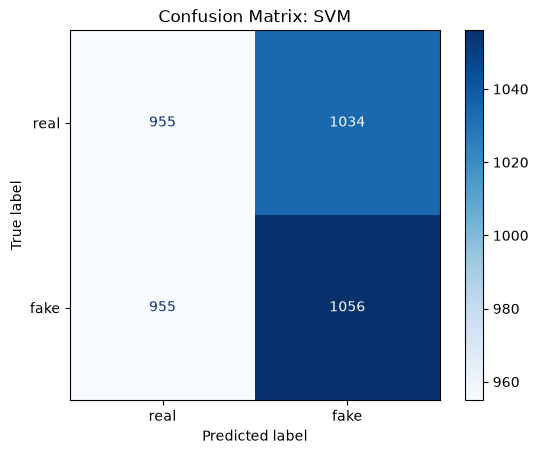

In [39]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: SVM")
plt.show()

- True Positive, correctly caught fake article: 1,056
- False Negative, fake article predicted as real: 955
- False Positive, real article predicted as fake: 1,034
- True Negative, correctly identified real article: 955

The four cells are almost equal. The model misses 955 fake articles (47%) and flags 1,034 real ones (52%), so it flags more real articles than it correctly clears.

For a trust-and-safety reviewer, this means 2,090 articles sent for checking, of which only 1,056 are fake. Compared with the Logistic Regression baseline, it catches 17 more fake articles with almost the same number of false alarms (1,034 vs 1,036).

## 8. Top-K Terms and Multicollinearity Check

With 867 terms, inspecting every term is impractical: PDP and ICE would need hundreds of plots, and an 867 × 867 correlation matrix cannot be read. We therefore focus on the 30 terms most linked to the fake/real label (K = 30), ranked by a chi-squared score on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. A higher score means a stronger link to the label, but it does not show the direction. We use it because it does not depend on any model, so every notebook can share the same list. Since TF-IDF weights are not counts, the scores are used only for ranking, not as significance tests.

In [40]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576492
1,particular,0.551777
2,significant,0.531097
3,model,0.517952
4,girl,0.503255
5,bring,0.501048
6,reflect,0.499708


The top seven terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words, not sensational language. Their scores are low and close together (0.50 to 0.58), so no term stands out.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [41]:
rng = np.random.RandomState(RANDOM_STATE)

# The SVM is slow to score, so PFI uses 1,000 test articles and PDP/ICE use 200
pfi_idx = rng.choice(X_test_dense.shape[0], size=1000, replace=False)
X_pfi, y_pfi = X_test_dense[pfi_idx].copy(), y_test.iloc[pfi_idx]

pdp_rows = rng.choice(X_test_dense.shape[0], size=200, replace=False)
X_sample = X_test_dense[pdp_rows]

The heatmap shows how strongly the weights of each pair of top terms move together, from −1 (one rises when the other falls) to 1 (they rise together). This matters for two methods: PFI can split importance between related terms, and PDP changes one term while holding the others fixed, which only gives realistic articles if the terms are not related.

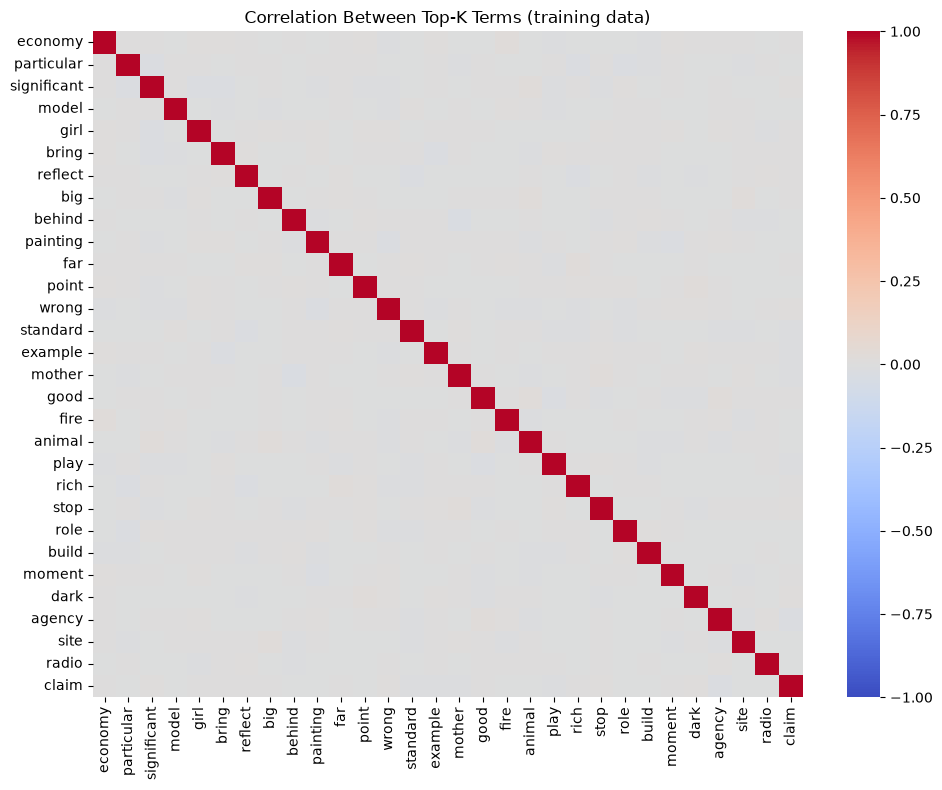

No pairs of terms with |correlation| > 0.5


In [42]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

Apart from the diagonal, where each term is compared with itself, every cell is pale gray, meaning a correlation close to 0, and no pair goes above 0.5. The top terms are close to independent, so we use PDP rather than ALE, and PFI should not be splitting importance between related terms. The check only covers the top 30 terms and linear relationships, so it does not rule out every dependence.

## 9. Global Importance (PFI and KernelSHAP)

### 9.1 Permutation Feature Importance (PFI)

Each of the 30 top terms is shuffled across the test articles, and we measure how much Fake-class recall drops. A large drop means the model relies on that term to catch fake articles. The SVM is slow to score, so PFI uses a random sample of 1,000 test articles and 3 shuffles per term. Its starting recall (0.5209) therefore differs slightly from the full test set.

In [43]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=3, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)

    def recall_now():
        return recall_score(y_true, (model.decision_function(X_dense) > 0).astype(int), pos_label=1)

    base = recall_now()
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_now())
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

# takes about 8 minutes
base_recall, pfi_df = permutation_recall_drop(svm_model, X_pfi, y_pfi, top_idx)
print(f"Recall before shuffling (1,000-article sample): {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling (1,000-article sample): 0.5209


,term,mean_recall_drop,std
2,significant,0.015905,0.004295
27,site,0.015905,0.001623
0,economy,0.011928,0.003247
9,painting,0.009940,0.005853
19,play,0.009278,0.002480
25,dark,0.009278,0.004686
8,behind,0.007290,0.003379


The sample contains about 500 fake articles, so each article caught or missed changes recall by about 0.002. The largest drops, for significant and site (0.016), mean about 8 more fake articles missed. economy follows at about 6 articles, and the rest at 4 to 5.

site has the most consistent drop, with a small standard deviation. painting and dark vary the most between shuffles.

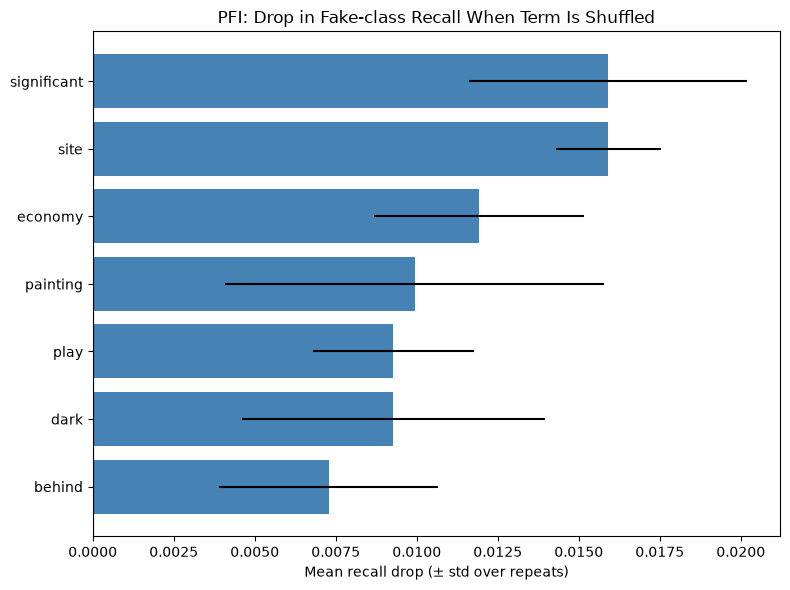

In [44]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

All error bars stay above zero, unlike for the tree models. The bars still overlap a lot, so the exact order should not be read closely. The check below tests whether these drops are larger than chance.

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [45]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)

# takes about 8 minutes
_, pfi_null = permutation_recall_drop(svm_model, X_pfi, y_pfi, other_idx)
print(pfi_null["mean_recall_drop"].describe())

count    30.000000
mean      0.001149
std       0.003069
min      -0.003976
25%      -0.000663
50%       0.000663
75%       0.002651
max       0.009940
Name: mean_recall_drop, dtype: float64


The 30 random terms give drops between −0.004 and 0.010, with a slightly positive average (0.001). Unlike a tree model, the RBF kernel uses every term when comparing articles, so even random terms have a small effect.

significant, site and economy drop recall by more than any random term (6 to 8 articles against at most 5), so their effects are real but small. painting is level with the largest random drop, and play, dark and behind fall within the random range, so their effects cannot be told apart from noise.

### 9.2 KernelSHAP (global view)

SHAP splits a prediction into a contribution from each term. TreeSHAP only works for tree models, and LinearSHAP only for linear ones, so for the RBF SVM we use KernelSHAP, which works with any model.

KernelSHAP treats the model as a black box. For one article, it creates many versions in which different combinations of terms are switched off, and runs the model on each. It then fits a weighted linear model to these results. The weights are chosen so that the fitted coefficients approximate each term's Shapley value: its average contribution across all combinations of other terms. Because it samples combinations rather than trying them all, the values are estimates, and they need many model calls per article.

This is slow for the SVM, and over all 867 terms the estimates are unstable, so we compute it only for the 30 top terms. "Switched off" means the word is absent (weight 0), and all other terms keep the article's own values. The starting value is therefore the article's decision value with its top 30 terms removed, not the model's average. Values are in decision-value units (positive pushes toward fake) and are computed for 100 test articles.

In [46]:
def kernel_shap_topk(model, x_row, top_idx, nsamples=500):
    # Shapley values for the top-K terms of ONE article; all other terms keep the article's own values
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1))
        full[:, top_idx] = Z
        return model.decision_function(full)
    explainer = shap.KernelExplainer(f, np.zeros((1, len(top_idx)), dtype=np.float32))
    values = explainer.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]
    return values, float(explainer.expected_value)

X_shap = X_sample[:100]

# takes about 5 minutes
results = [kernel_shap_topk(svm_model, X_shap[i], top_idx) for i in range(len(X_shap))]
sv_topk = np.array([r[0] for r in results])
base_values = np.array([r[1] for r in results])
print("SHAP values shape:", sv_topk.shape)

SHAP values shape: (100, 30)


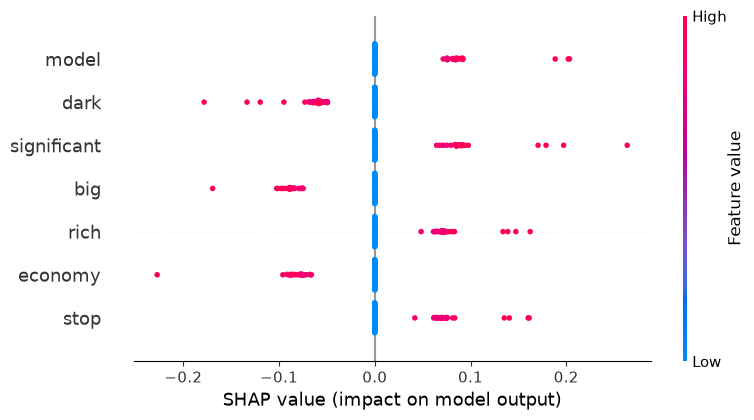

In [47]:
shap.summary_plot(sv_topk, X_shap[:, top_idx], feature_names=list(top_terms), max_display=7)

In [48]:
shap_importance = pd.DataFrame({
    "term": top_terms,
    "mean_abs_shap": np.abs(sv_topk).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
3,model,0.026012
25,dark,0.025408
2,significant,0.025016
7,big,0.022709
20,rich,0.021933
0,economy,0.021555
21,stop,0.021205


Each dot is one article. Its position shows how much a term moved the decision value toward fake (right) or real (left), and its color shows the term's weight: red for high, blue for low or absent.

Every blue dot is exactly 0: if the word is absent, switching it off changes nothing. The red dots form tight groups, so a term has almost the same effect in every article that contains it. model, significant, rich, stop and agency push toward fake by about 0.06 to 0.09, and dark and big push toward real by about the same amount. The few dots further out, up to 0.26, are articles where the word carries more weight.

The average values in the table are close together (0.021 to 0.026), so no term stands out. The size of each push also matches the PDP below, which gives about 0.08 for a word present at a typical weight.

significant is the only term near the top of both SHAP and PFI. dark also appears in both, but its PFI effect is within noise. site and economy have real PFI effects but are not in SHAP's top seven. SHAP is based on only 100 articles, so terms that appear in few of them rank lower. The two methods also measure different things: SHAP measures how far a term moves the decision value, and PFI how much catching fake articles suffers.

## 10. Feature Effects (PDP)

PDP shows the model's average decision value (positive means fake) as one term's weight increases, so it shows which direction a term pushes and how strongly. Because the top terms are not correlated, we use PDP rather than ALE. It uses a random sample of 200 test articles.

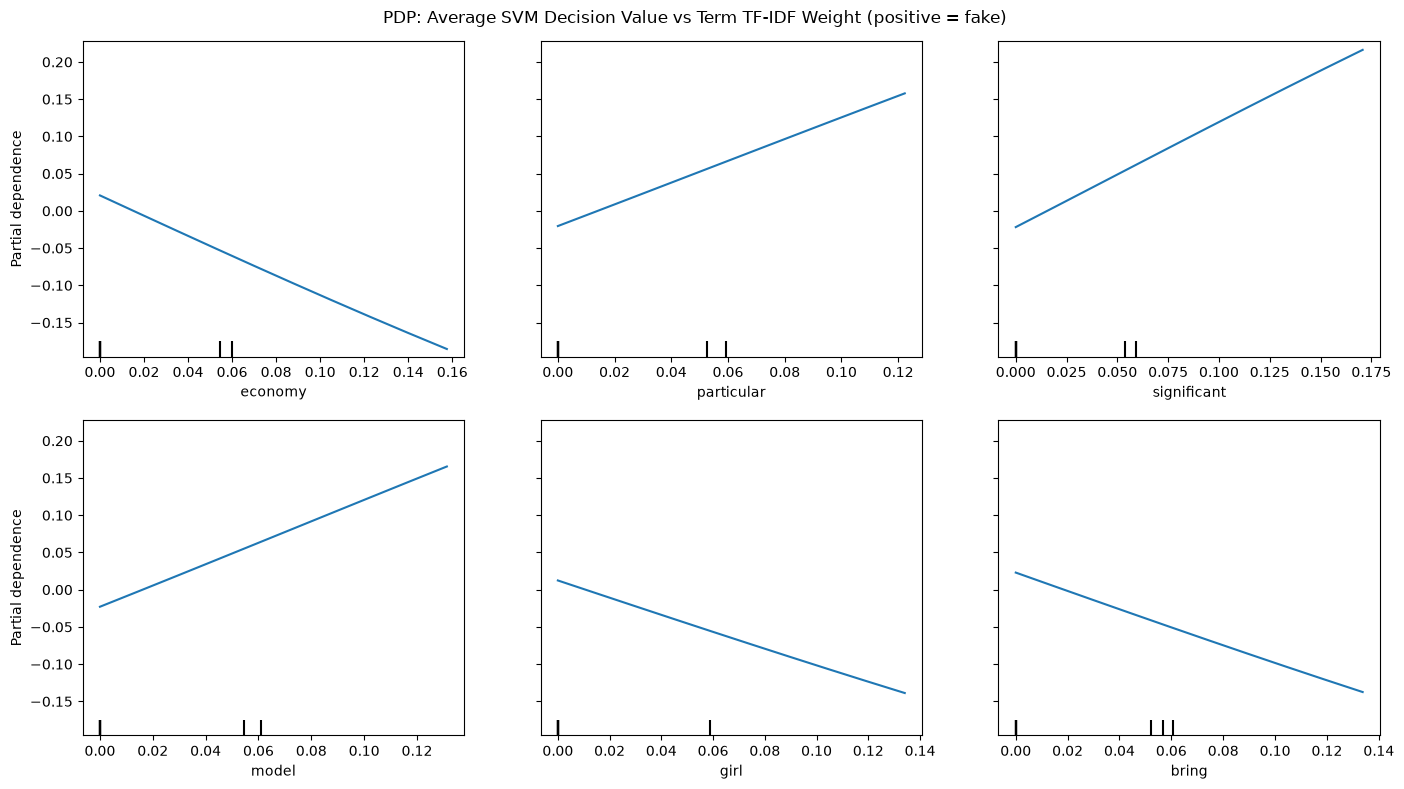

In [49]:
pdp_idx = list(top_idx[:6])

pdp_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    response_method="decision_function",
    grid_resolution=10,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
pdp_display.figure_.set_size_inches(14, 8)
pdp_display.figure_.suptitle("PDP: Average SVM Decision Value vs Term TF-IDF Weight (positive = fake)")
plt.tight_layout()
plt.show()

Each curve is a straight line, because the RBF kernel changes smoothly as a word's weight grows. Real articles only have weights of 0 (word absent) or about 0.055 and above (word present), so what matters in practice is the change at about 0.06.

particular, significant and model raise the decision value, pushing toward fake, while economy, girl and bring lower it, pushing toward real.

At a weight of 0.06, each term moves the average decision value by about 0.07 to 0.09. Since most decision values lie between −1 and 1, a move of 0.08 changes the sigmoid score by only about 2 percentage points.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, showing whether a term affects every article the same way.

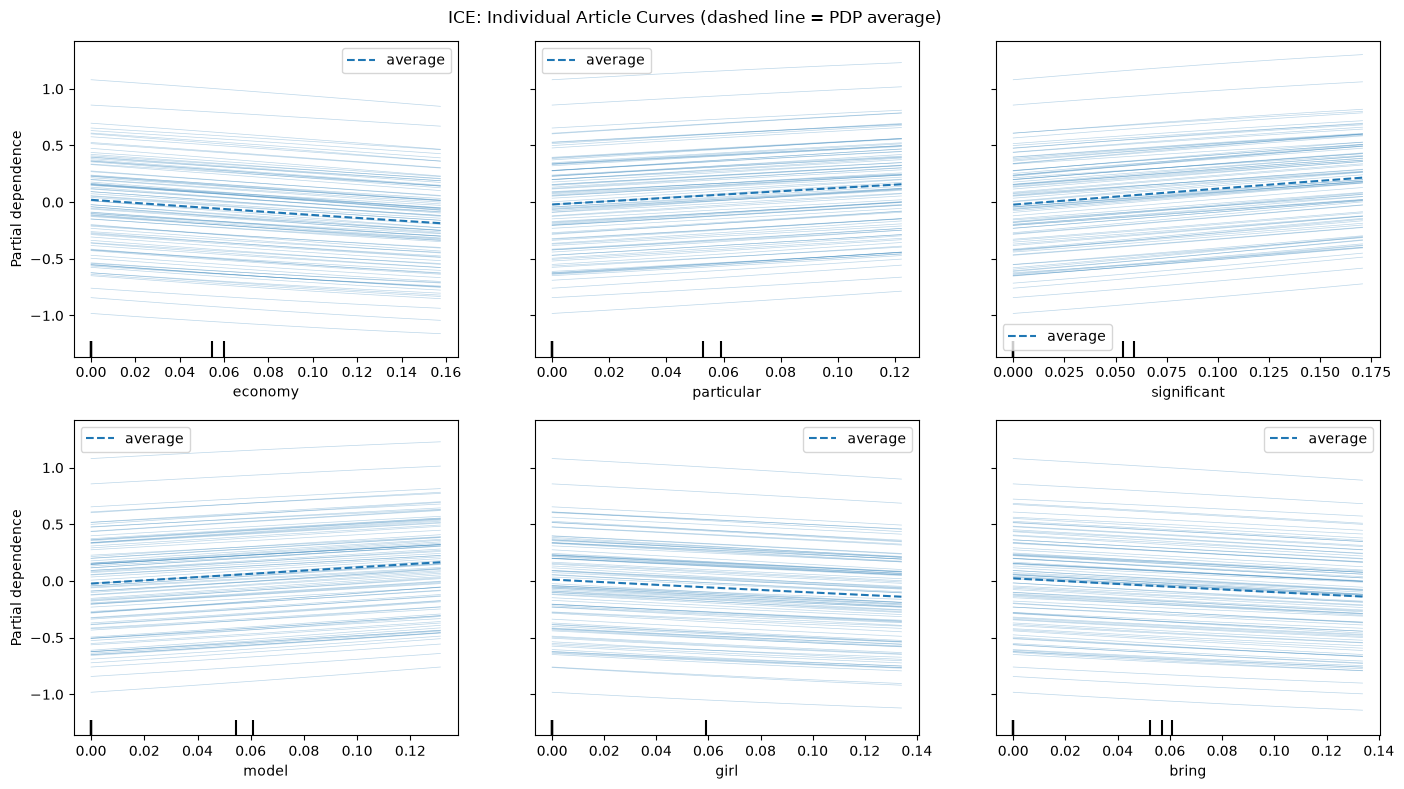

In [50]:
ice_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    response_method="decision_function",
    subsample=100,
    grid_resolution=10,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the PDP average. The lines start anywhere from about −1.0 to 1.1, because each decision value also depends on the article's other words. Every line has almost the same slope as the average, so no article reacts differently. The centered version below shows this more clearly.

### 11.1 Centered ICE

Centered ICE shifts every line to start at 0, so each line shows only how much the decision value changes as the term's weight increases in that article.

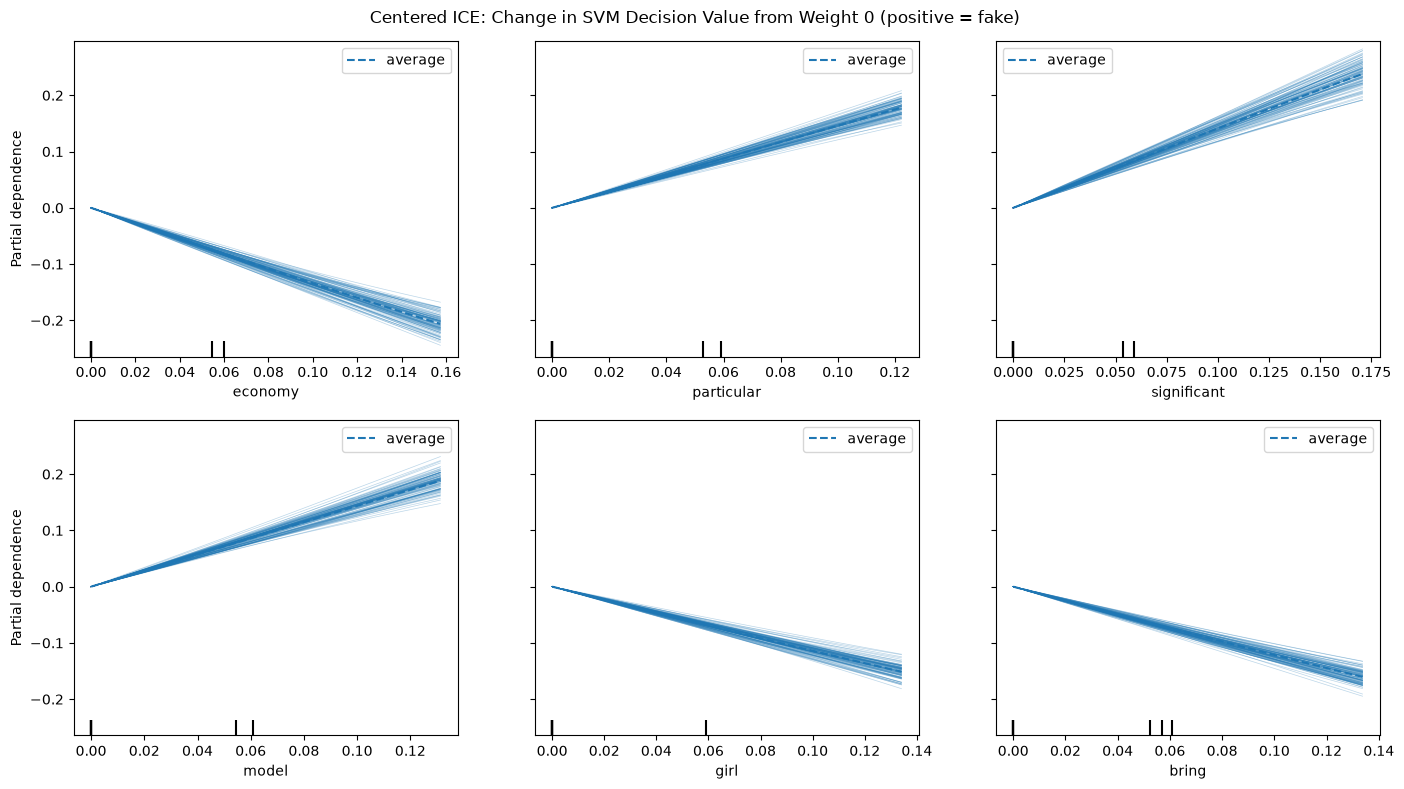

In [51]:
cice_display = PartialDependenceDisplay.from_estimator(
    svm_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    response_method="decision_function",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in SVM Decision Value from Weight 0 (positive = fake)")
plt.tight_layout()
plt.show()

Every line is straight, and all lines in a panel fan out only slightly. No article goes in the opposite direction from the average. For economy, every article's decision value falls, by between 0.17 and 0.24 at the highest weight. The other terms are similarly consistent.

So the SVM gives each term almost the same effect in every article, whatever else the article contains. At these small TF-IDF weights, the RBF kernel behaves almost like a linear model, adding up one fixed push per word.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the model overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the model was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

The score shown for each article is the sigmoid of the SVM's decision value. It ranks articles correctly but is not a calibrated probability.

In [52]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    # LIME needs probabilities, so the SVM decision value is passed through a sigmoid
    s = svm_model.decision_function(tfidf.transform(texts).toarray().astype(np.float32))
    p = 1 / (1 + np.exp(-s))
    return np.column_stack([1 - p, p])

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = 1 / (1 + np.exp(-scores_test))      # probability-like score, not calibrated

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains a pool of random test articles and picks the 5 whose explanations together cover the most words with the least repetition. The SVM is slow to score, so the pool is 60 articles. SP-LIME does not look at the label or category, so we check those afterwards.

In [53]:
N_CANDIDATES = 60
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

# takes about 3 minutes
sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=500,
    top_labels=None          # explain the fake class (label 1) for every article
)
sp_idx = cand_idx[sp.V]      # positions of the picked articles in the test set

In [54]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "category": [df.loc[y_test.index[i], "category"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "score": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

,category,true_label,score,outcome
0,Entertainment,real,0.585,"FP (real, flagged)"
1,Science,real,0.383,"TN (real, correct)"
2,Business,fake,0.541,"TP (fake, caught)"
3,Business,fake,0.437,"FN (fake, missed)"
4,Sports,real,0.600,"FP (real, flagged)"


SP-LIME pick 1 | score = 0.585


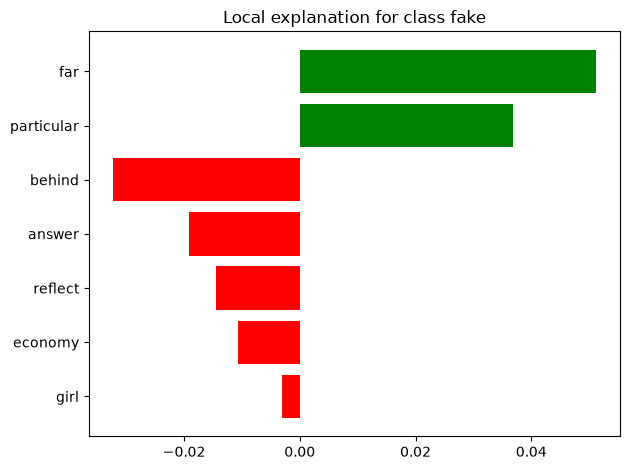

SP-LIME pick 2 | score = 0.383


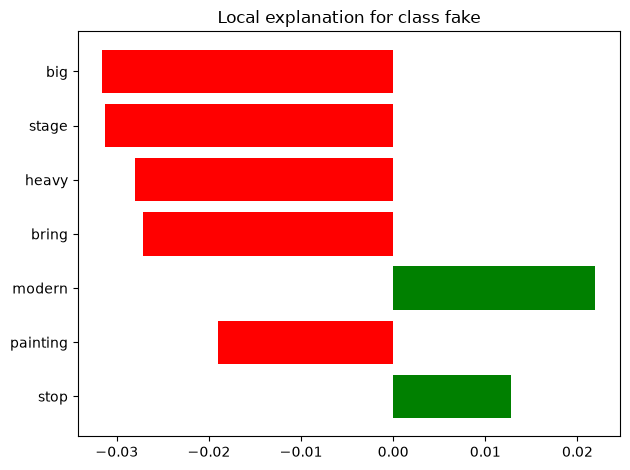

SP-LIME pick 3 | score = 0.541


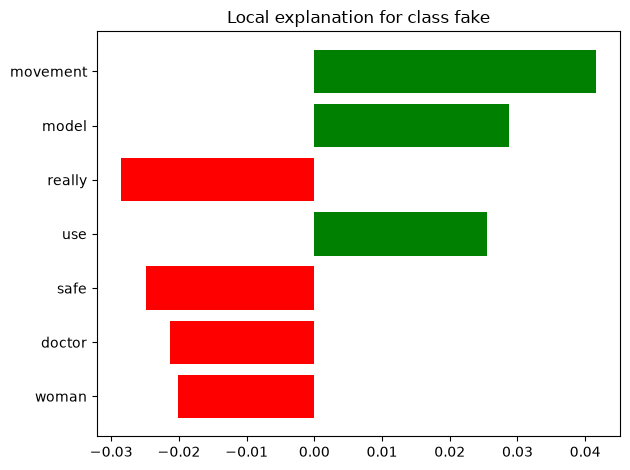

SP-LIME pick 4 | score = 0.437


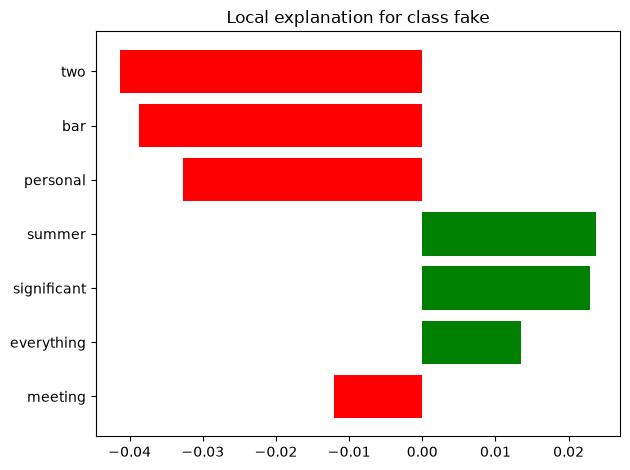

SP-LIME pick 5 | score = 0.600


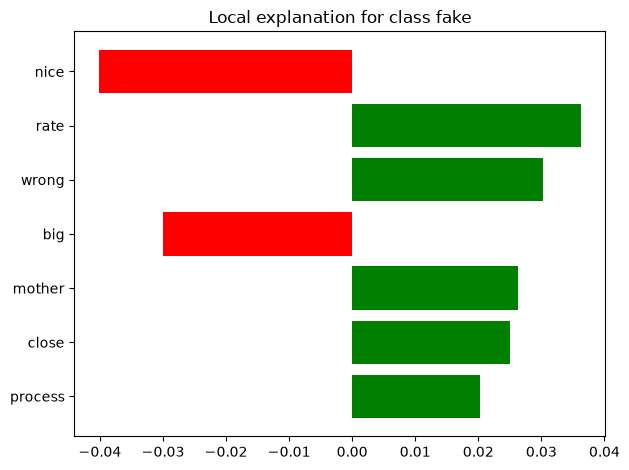

In [55]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | score = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

The five picks come from four categories and include three real and two fake articles, but this mix is chance. All five scores are between 0.383 and 0.600, so the model was unsure about every one.

**Wrongly flagged real articles (picks 1 and 5).** In pick 1, far and particular push toward fake slightly more than behind, answer, reflect, economy and girl push toward real. In pick 5, rate, wrong, mother, close and process (about 0.14 in total) clearly outweigh nice and big.

**Correct real article (pick 2).** big, stage, heavy, bring and painting push toward real (about 0.14), far more than modern and stop push toward fake.

**Caught fake article (pick 3).** movement, model and use push toward fake about as much as really, safe, doctor and woman push toward real. The words shown are balanced, so the words not shown decided the outcome.

**Missed fake article (pick 4).** two, bar, personal and meeting pull toward real (about 0.12), about twice as much as summer, significant and everything push toward fake.

Only big appears in more than one pick, toward real both times. Where a word also appears in the global results (particular, economy, girl, bring, model, significant, big, stop), it pushes the same way as there.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the score changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | score = 0.778


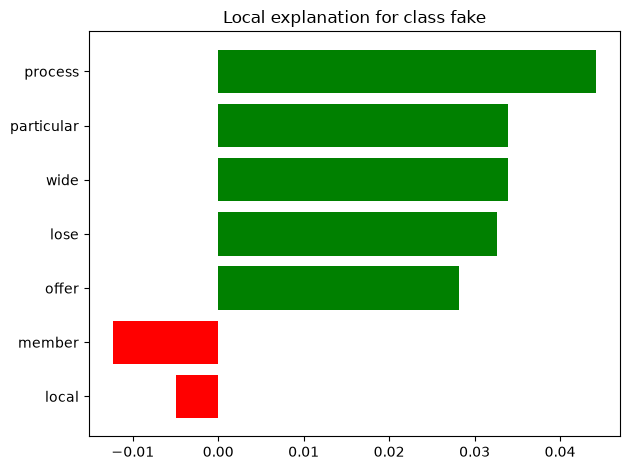

False Negative (fake, missed) | score = 0.208


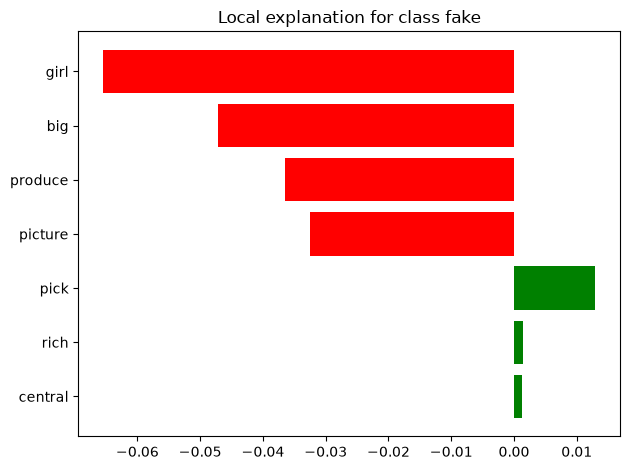

False Positive (real, flagged) | score = 0.829


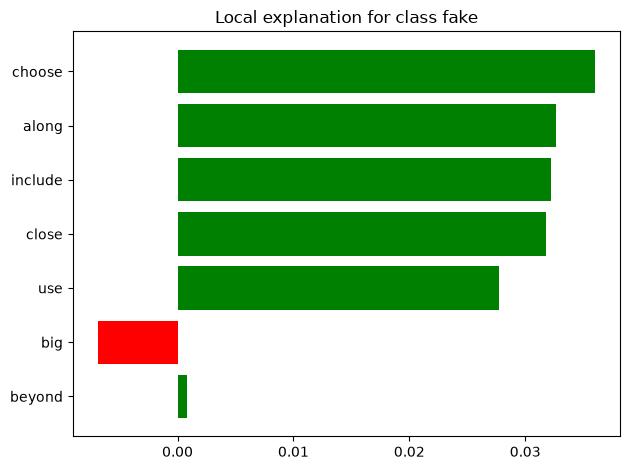

In [56]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=500, labels=(1,)
    )
    print(f"{name} | score = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

These are the most extreme articles in each group.

**True Positive (score 0.778).** process, particular, wide, lose and offer push toward fake (0.028 to 0.044 each), and only member and local push slightly toward real. No single word dominates.

**False Negative (score 0.208).** girl (0.066) and big (0.047) pull hardest toward real, followed by produce and picture. Only pick pushes toward fake by a noticeable amount. girl and big also point toward real in the global results.

**False Positive (score 0.829).** choose, along, include, close and use push toward fake (0.028 to 0.036 each), with almost nothing pushing the other way. This is the highest score in the whole test set, and it belongs to a real article.

All three predictions come from several ordinary words of similar size, which fits a model that adds up one small push per word. The model's single most confident fake call is wrong, so a high score does not mean a reliable answer.

### 12.3 KernelSHAP Waterfall (the missed fake article)

LIME approximates the model around one article, while KernelSHAP splits the model's own output into contributions that add up exactly. Here it explains the missed fake article from 12.2, so the two methods can be compared on the same case. As in 9.2, only the top 30 terms are explained, and the values are in decision-value units.

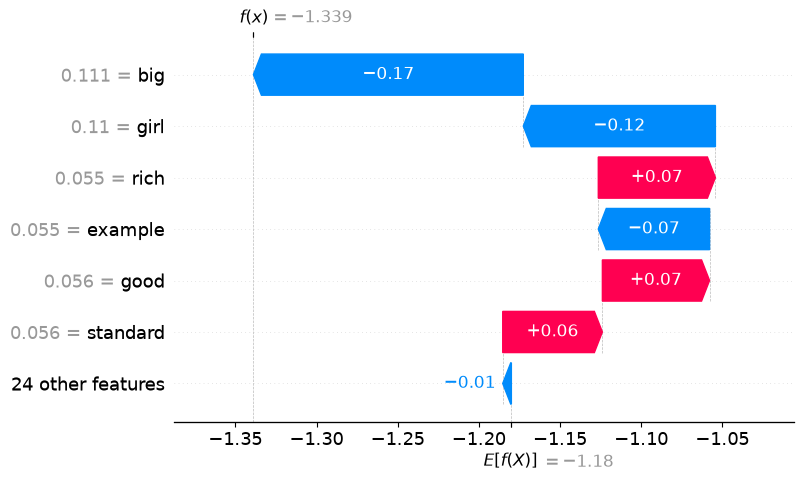

In [57]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx]                      # one row, 1-D

sv_fn, base_fn = kernel_shap_topk(svm_model, x_fn, top_idx)

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn, base_values=base_fn,
        data=x_fn[top_idx], feature_names=list(top_terms)
    ),
    max_display=7
)

Here the starting value (shown as E[f(X)] = −1.18) is not the model's average. It is this article's decision value with its top 30 terms removed. So before any top term is counted, the article is already firmly on the real side, because of the words outside the top 30. The top terms then move it only a little further, to −1.339 (score 0.208).

big (−0.17) and girl (−0.12) push hardest toward real, followed by example. rich, good and standard push toward fake by about 0.06 to 0.07 each. The other 24 top terms add almost nothing.

SHAP and LIME agree on the two main words, big and girl, though in the opposite order, and both show rich slightly toward fake. LIME's produce and picture are not in the top 30, so SHAP cannot show them. This is the limit of explaining only the top terms: for this article, most of the push toward real comes from words outside the list.

## 13. Summary

The SVM catches 53% of fake articles (recall 0.5251), but its accuracy (0.5028) is exactly what a model calling every article fake would get, and its ROC AUC is 0.507. Its recall simply matches the 52% of articles it labels as fake. Almost every training article (99%) became a support vector, and training recall (0.95) is far above test recall, so the model memorized the training data without finding a real pattern.

The explanation methods agree that no word matters much:
- **PFI:** significant, site and economy drop recall by more than any random term, but by at most about 8 of 500 fake articles. The other top terms cannot be told apart from noise.
- **KernelSHAP:** each top term moves the decision value by about 0.06 to 0.09 when present, roughly 2 percentage points of score, and no term stands out.
- **PDP and ICE:** each term has a straight-line effect that is almost identical in every article, so the SVM behaves almost like a linear model.
- **LIME:** predictions come from several ordinary words of similar size, and the model's most confident fake call is a real article.
- **SHAP waterfall:** for the missed fake article, SHAP and LIME agree on the main words, big and girl, but most of the push toward real comes from words outside the top 30.

Where the methods share a term, they agree on its direction: significant, particular and model lean toward fake, and economy, girl, big and bring toward real.

Overall, the SVM does no better than the baseline, which suggests the text carries very little signal. All results come from one train/test split, so small differences between models should not be over-read.